# Musanga V2 — Notebook 02 | Frozen U-Net crown evaluation and illumination sensitivity

**Read-only CPU benchmark.** Tests the frozen production U-Net against the independent merged Luki crown labels (179 Musanga, 185 non-Musanga), and characterizes probability/illumination relationships at all five UAV sites. Uses existing **native-resolution UAV probability maps** and raster geometry, with no retraining or new full-mosaic inference.

Run after V2 Notebooks 00 and 01. Every output goes to `MyDrive/Colab Notebooks/Musanga/KVO_work/V2/02_frozen_baseline/`.

**Scientific safeguards:** The production U-Net was trained on MOS, Yoko, Yangambi and Baego. Any metrics computed there are **apparent training-domain diagnostics**, not independent site transfer results. **Luki is the genuine independent evaluation**. Use both training-pooled and *site-relative* illumination strata because Luki is globally brighter than the other forests. Crown-level segmentation labels are used only inside annotated crowns, not as whole-scene reference masks.

Sections are numbered and independently inspectable after the setup cell.

## 00 — Source contract and evaluation safeguards

CPU-only. This notebook reuses the **frozen full-resolution probability maps**; it does not rerun the U-Net, alter maps or retrain. Luki is an independent external evaluation site. The original four training forests were included in the frozen production U-Net, so their metrics are **apparent/in-sample** and cannot be presented as independent validation.

In [2]:
%pip -q install geopandas pyogrio rasterio shapely scipy scikit-learn matplotlib pandas
from pathlib import Path
import json,math,hashlib
import numpy as np,pandas as pd,geopandas as gpd,rasterio,matplotlib.pyplot as plt
from rasterio.features import geometry_mask
from rasterio.windows import Window,from_bounds
from scipy.stats import spearmanr
from sklearn.metrics import (roc_auc_score,average_precision_score,balanced_accuracy_score,
    precision_score,recall_score,f1_score,confusion_matrix,brier_score_loss)
from IPython.display import display
from google.colab import drive
MY=Path("/content/drive/MyDrive")
if not MY.exists():drive.mount("/content/drive")
ROOT=MY/"Colab Notebooks"/"Musanga"
GEO=ROOT/"data"/"Geo_Ref";AD=GEO/"Annotations"
V2=ROOT/"KVO_work"/"V2"
OUT=V2/"02_frozen_baseline";OUT.mkdir(parents=True,exist_ok=True)
REF=V2/"01_reference_splits";MERGED=REF/"01_Luki_frozen_external_reference.gpkg"
MAPS=ROOT/"KVO_work"/"KVO_04_final_multisite"/"probability_maps"
assert MERGED.exists(),f"Run V2 Notebook 01, section 02: {MERGED}"
LUKI_VERSION_MANIFEST=REF/"01_luki_current_reference_version.json"
assert LUKI_VERSION_MANIFEST.exists(),"Run updated V2 Notebook 01 Section 02 first"
LUKI_REFERENCE=json.loads(LUKI_VERSION_MANIFEST.read_text())
LUKI_VERSION=LUKI_REFERENCE["reference_id"]
# Keep old baseline outputs untouched; new reference versions get separate folders.
OUT=OUT/"by_luki_reference"/LUKI_VERSION
OUT.mkdir(parents=True,exist_ok=True)
print("Using immutable external Luki reference version",LUKI_VERSION)

assert (REF/"01_crown_illumination.csv").exists(),f"Run V2 Notebook 01, section 05."
SITES={
 "MOS_1_2":("MOS_1_2_kvo.tif","Tree_Annotations_MOS_1_2_kvo.shp"),
 "Yoko":("Yoko_kvo_georef.tif","Tree_Annotations_Yoko_kvo_georef.shp"),
 "Yangambi":("Yangambi_georef.tif","Tree_Annotation_Yangambi_georef.shp"),
 "Baego":("Baego_georef.tif","Tree_Annotation_Baego.shp"),
 "Luki":("Luki.tif",None)}
MIN_AREA=5.0;P_SCALE=10000.;P_NODATA=65535
CROWN_SCORE_THRESHOLD=.50  # classification from mean U-Net probability WITHIN annotated crown
PIXEL_COVER_THRESHOLD=.50  # descriptive fraction of predicted-Musanga pixels within each crown
MAX_CROWN_WINDOW=2048
MIN_CROWN_VALID_PIXELS=10
print("V2 frozen diagnostic output:",OUT)
print("Scope: external Luki evaluation and descriptive TRAINING-site diagnostics, no fitting.")


Using immutable external Luki reference version d957b570055bf5dd
V2 frozen diagnostic output: /content/drive/MyDrive/Colab Notebooks/Musanga/KVO_work/V2/02_frozen_baseline/by_luki_reference/d957b570055bf5dd
Scope: external Luki evaluation and descriptive TRAINING-site diagnostics, no fitting.


## 01 — Reconstruct the immutable crown reference

Read precisely the same eligible polygons used in Notebook 01. Cross-check IDs against saved split registers and use the merged **364-crown Luki** reference. No label source is silently added or omitted.

In [3]:
CROWNS={}
for site,(rgb,ann) in SITES.items():
    if site=="Luki":
        g=gpd.read_file(MERGED,layer="external_evaluation")
        assert len(g)==int(LUKI_REFERENCE["crowns"]), "Luki reference metadata disagrees with dataset"
        assert int((g.class_id==1).sum())==int(LUKI_REFERENCE["musanga"])
        g["label"]=(g.class_id==1).astype(int)
        g["crown_id"]=g["crown_id"].astype(str)
        g["split"]="external"
    else:
        g=gpd.read_file(AD/ann)
        with rasterio.open(GEO/rgb) as ds:
            assert g.crs is not None
            if g.crs!=ds.crs:g=g.to_crs(ds.crs)
            footprint=__import__("shapely.geometry",fromlist=["box"]).box(*ds.bounds)
        valid=(g.geometry.notna())&(~g.geometry.is_empty)&g.geometry.is_valid
        g=g.loc[valid].copy()
        class_ids=pd.to_numeric(g.Class_ID,errors="coerce")
        g=g.loc[class_ids.notna()].copy()
        g["class_id"]=class_ids.loc[g.index].astype(int)
        g["area_m2"]=g.geometry.area
        g=g.loc[(g.area_m2>=MIN_AREA)&g.geometry.intersects(footprint)].copy()
        g["source_row"]=g.index.astype(str)
        g["crown_id"]=site+":"+g.source_row
        g["label"]=(g.class_id==1).astype(int)
        register=pd.read_csv(REF/f"01_{site}_split_register.csv",dtype={"crown_id":"string"})
        assert set(g.crown_id)==set(register.crown_id),f"{site}: source annotation/split register changed"
        g=g.merge(register[["crown_id","split"]],on="crown_id",how="left",validate="one_to_one")
        assert g.split.notna().all()
    assert g.crown_id.is_unique
    CROWNS[site]=g
    print(site,"reference crowns:",len(g),"Musanga:",int(g.label.sum()),flush=True)
illum=pd.read_csv(REF/"01_crown_illumination.csv",dtype={"crown_id":"string"})
assert illum.crown_id.is_unique, "Duplicate illumination rows in Notebook 01 outputs"


MOS_1_2 reference crowns: 1132 Musanga: 529
Yoko reference crowns: 1792 Musanga: 1016
Yangambi reference crowns: 944 Musanga: 465
Baego reference crowns: 749 Musanga: 346
Luki reference crowns: 479 Musanga: 249


## 02 — Crown-aligned frozen U-Net probability audit

Read one bounded UAV window per crown from the established full-resolution probability map. Report **mean predicted probability**, **fraction of crown pixels above 0.5**, number of valid prediction pixels and reference class. Class evaluation uses the mean probability; fractional cover is a separate diagnostic.

In [4]:
def crown_stats02(geom,src):
    window=from_bounds(*geom.bounds,transform=src.transform).round_offsets().round_lengths()
    x0=max(0,int(window.col_off));y0=max(0,int(window.row_off))
    x1=min(src.width,int(math.ceil(window.col_off+window.width)))
    y1=min(src.height,int(math.ceil(window.row_off+window.height)))
    w=x1-x0;h=y1-y0
    if w<=0 or h<=0:return dict(mean_p=np.nan,cover_p05=np.nan,valid_px=0,coverage=np.nan,qa="outside")
    if w>MAX_CROWN_WINDOW or h>MAX_CROWN_WINDOW:
        return dict(mean_p=np.nan,cover_p05=np.nan,valid_px=0,coverage=np.nan,qa="window_too_large")
    win=Window(x0,y0,w,h)
    within=geometry_mask([geom],out_shape=(h,w),transform=src.window_transform(win),invert=True)
    denom=int(within.sum())
    if denom<1:return dict(mean_p=np.nan,cover_p05=np.nan,valid_px=0,coverage=0,qa="subpixel_geometry")
    z=src.read(1,window=win)
    v=within&(z!=P_NODATA)&(z>=0)&(z<=P_SCALE)
    count=int(v.sum())
    coverage=count/denom
    if count<MIN_CROWN_VALID_PIXELS or coverage<.90:
        return dict(mean_p=np.nan,cover_p05=np.nan,valid_px=count,coverage=coverage,qa="insufficient_valid")
    p=z[v].astype(np.float32)/P_SCALE
    return dict(mean_p=float(p.mean()),cover_p05=float(np.mean(p>=PIXEL_COVER_THRESHOLD)),
                valid_px=count,coverage=coverage,qa="ok")

ROWS=[]
for site,g in CROWNS.items():
    srcpath=MAPS/f"{site}_musanga_probability_uint16_FULL.tif"
    assert srcpath.exists(),f"Missing frozen probability map: {srcpath}"
    with rasterio.open(GEO/SITES[site][0]) as rgb,rasterio.open(srcpath) as probability:
        assert rgb.transform==probability.transform and rgb.crs==probability.crs
        assert rgb.width==probability.width and rgb.height==probability.height
        assert probability.count==1 and probability.dtypes[0]=="uint16"
        for _,r in g.iterrows():
            stats=crown_stats02(r.geometry,probability)
            ROWS.append(dict(site=site,crown_id=str(r.crown_id),label=int(r.label),
                source_dataset=str(r.get("source_dataset","training")),
                split=str(r.split),**stats))
    print("Frozen crown predictions read:",site,len(g),flush=True)
CROWN_PRED=pd.DataFrame(ROWS)
CROWN_PRED=CROWN_PRED.merge(illum[["site","crown_id","median_luminance",
                                 "illumination_stratum","valid_rgb_pixels"]],
                          on=["site","crown_id"],how="left",validate="one_to_one")
assert CROWN_PRED.median_luminance.notna().any()
CROWN_PRED.to_csv(OUT/"02_frozen_crown_predictions.csv",index=False)
display(pd.crosstab(CROWN_PRED.site,CROWN_PRED.qa))


Frozen crown predictions read: MOS_1_2 1132
Frozen crown predictions read: Yoko 1792
Frozen crown predictions read: Yangambi 944
Frozen crown predictions read: Baego 749
Frozen crown predictions read: Luki 479


qa,ok
site,
Baego,749
Luki,479
MOS_1_2,1132
Yangambi,944
Yoko,1792


## 03 — Absolute and site-relative illumination strata

The **training-pooled thresholds classify nearly all Luki crowns as bright**, making them unsuitable for diagnosing its internal cloud-shadow patches. Report both the fixed training-reference strata and **within-site brightness quartiles**, plus continuous brightness. Quartiles are defined without looking at model accuracy.

In [5]:
CROWN_PRED["site_relative_light"]="unknown"
LIGHT_CUTS=[]
for site,g in CROWN_PRED.groupby("site"):
    valid=g.median_luminance.dropna()
    q1,q3=valid.quantile([.25,.75]).to_numpy()
    LIGHT_CUTS.append(dict(site=site,n_brightness=len(valid),q25=float(q1),
                           q75=float(q3),site_median=float(valid.median())))
    mask=(CROWN_PRED.site==site)&CROWN_PRED.median_luminance.notna()
    vals=CROWN_PRED.loc[mask,"median_luminance"]
    CROWN_PRED.loc[mask,"site_relative_light"]=np.where(vals<=q1,"darkest_25pct",
         np.where(vals>=q3,"brightest_25pct","middle_50pct"))
LIGHT_CUTS=pd.DataFrame(LIGHT_CUTS)
LIGHT_CUTS.to_csv(OUT/"02_site_specific_illumination_cutoffs.csv",index=False)
CROWN_PRED.to_csv(OUT/"02_frozen_crown_predictions.csv",index=False)
display(LIGHT_CUTS.round(3))
display(pd.crosstab(CROWN_PRED.site,CROWN_PRED.site_relative_light))
display(pd.crosstab(CROWN_PRED.site,CROWN_PRED.illumination_stratum))


,site,n_brightness,q25,q75,site_median
0,Baego,749,0.432,0.538,0.483
1,Luki,479,0.542,0.659,0.592
2,MOS_1_2,1132,0.409,0.516,0.457
3,Yangambi,944,0.390,0.500,0.441
4,Yoko,1792,0.406,0.498,0.453


site_relative_light,brightest_25pct,darkest_25pct,middle_50pct
site,,,
Baego,188,188,373
Luki,120,120,239
MOS_1_2,283,283,566
Yangambi,236,236,472
Yoko,449,448,895


illumination_stratum,bright,dark,intermediate
site,,,
Baego,208,111,430
Luki,385,2,92
MOS_1_2,243,229,660
Yangambi,162,269,513
Yoko,241,372,1179


## 04 — Species-discrimination metrics with external-test designation

Calculate ROC-AUC, average precision, precision/recall, balanced accuracy, F1, Brier score and confusion counts at crown level. **Only Luki is externally independent for this frozen model.** Small strata are flagged; no thresholds are tuned on Luki.

In [6]:
def score02(g):
    g=g[(g.qa=="ok")&g.mean_p.notna()].copy()
    if len(g)<2:return dict(n=len(g))
    y=g.label.to_numpy(dtype=int)
    p=g.mean_p.to_numpy(dtype=float)
    pred=(p>=CROWN_SCORE_THRESHOLD).astype(int)
    cm=confusion_matrix(y,pred,labels=[0,1])
    tn,fp,fn,tp=cm.ravel()
    return dict(n=len(g),musanga=int(y.sum()),other=int((1-y).sum()),
        prevalence=float(y.mean()),mean_score=float(p.mean()),
        auc=float(roc_auc_score(y,p)) if len(np.unique(y))==2 else np.nan,
        average_precision=float(average_precision_score(y,p)) if y.sum()>0 else np.nan,
        precision=float(precision_score(y,pred,zero_division=0)),
        recall=float(recall_score(y,pred,zero_division=0)),
        specificity=float(tn/max(1,tn+fp)),
        balanced_accuracy=float(balanced_accuracy_score(y,pred)) if len(np.unique(y))==2 else np.nan,
        f1=float(f1_score(y,pred,zero_division=0)),
        brier=float(brier_score_loss(y,p)),
        tp=int(tp),tn=int(tn),fp=int(fp),fn=int(fn))
RESULTS=[]
for site in SITES:
    base=CROWN_PRED[CROWN_PRED.site==site]
    RESULTS.append(dict(site=site,stratum_type="all",stratum="all",
                        evaluation="independent_external" if site=="Luki" else "training_site_apparent",
                        **score02(base)))
    for typ in ["site_relative_light","illumination_stratum"]:
        for category,sub in base.groupby(typ):
            RESULTS.append(dict(site=site,stratum_type=typ,stratum=str(category),
                evaluation="independent_external" if site=="Luki" else "training_site_apparent",
                **score02(sub)))
METRICS=pd.DataFrame(RESULTS)
METRICS.to_csv(OUT/"02_frozen_crown_metrics_by_illumination.csv",index=False)
print("Whole-site metrics:")
display(METRICS[METRICS.stratum_type=="all"][["site","evaluation","n","musanga","other",
    "auc","average_precision","precision","recall","specificity","balanced_accuracy","f1",
    "fp","fn"]].round(3))
print("Luki relative illumination performance (interpret n and class prevalence):")
display(METRICS[(METRICS.site=="Luki")&
    (METRICS.stratum_type=="site_relative_light")].round(3))


Whole-site metrics:


,site,evaluation,n,musanga,other,auc,average_precision,precision,recall,specificity,balanced_accuracy,f1,fp,fn
0,MOS_1_2,training_site_apparent,1132,529,603,0.978,0.975,0.903,0.947,0.910,0.929,0.924,54,28
7,Yoko,training_site_apparent,1792,1016,776,0.970,0.979,0.955,0.895,0.945,0.920,0.924,43,107
14,Yangambi,training_site_apparent,944,465,479,0.993,0.994,0.982,0.923,0.983,0.953,0.951,8,36
21,Baego,training_site_apparent,749,346,403,0.970,0.959,0.869,0.936,0.878,0.907,0.901,49,22
28,Luki,independent_external,479,249,230,0.981,0.974,0.989,0.751,0.991,0.871,0.854,2,62


Luki relative illumination performance (interpret n and class prevalence):


,site,stratum_type,stratum,evaluation,n,musanga,other,prevalence,mean_score,auc,...,precision,recall,specificity,balanced_accuracy,f1,brier,tp,tn,fp,fn
29,Luki,site_relative_light,brightest_25pct,independent_external,120,19,101,0.158,0.049,0.933,...,1.000,0.263,1.000,0.632,0.417,0.105,5,101,0,14
30,Luki,site_relative_light,darkest_25pct,independent_external,120,104,16,0.867,0.695,0.979,...,0.989,0.846,0.938,0.892,0.912,0.086,88,15,1,16
31,Luki,site_relative_light,middle_50pct,independent_external,239,126,113,0.527,0.379,0.981,...,0.989,0.746,0.991,0.869,0.851,0.106,94,112,1,32


## 05 — Error versus illumination and crown-level diagnostics

Test whether dark crowns have elevated false-positive scores, particularly **non-Musanga crowns in Luki**. Make density-free scatter and binned error summaries. No inference about cloud shadows is possible from a site-mean relationship alone.

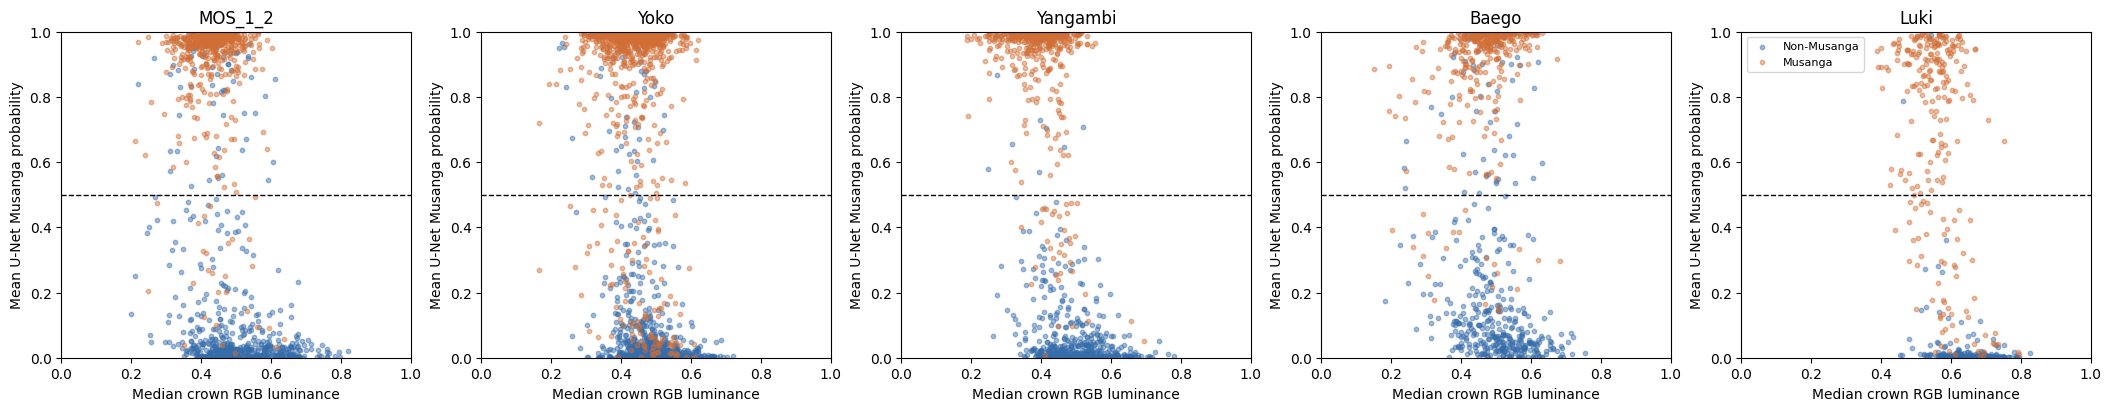

,site,label,n,brightness_vs_musanga_score_spearman_rho,median_probability,median_brightness
0,Baego,0,403,-0.393,0.081,0.501
1,Baego,1,346,0.365,0.964,0.473
2,Luki,0,230,-0.372,0.005,0.646
3,Luki,1,249,-0.247,0.842,0.559
4,MOS_1_2,0,603,-0.265,0.026,0.486
5,MOS_1_2,1,529,0.088,0.966,0.433
6,Yangambi,0,479,-0.238,0.020,0.487
7,Yangambi,1,465,-0.045,0.979,0.404
8,Yoko,0,776,-0.276,0.017,0.479
9,Yoko,1,1016,-0.144,0.979,0.431


Luki FALSE-POSITIVE risk by within-site relative brightness (non-Musanga crowns):


,crowns,median_p,mean_p,false_positive_rate
site_relative_light,,,,
brightest_25pct,101,0.004,0.009,0.000
darkest_25pct,16,0.011,0.098,0.062
middle_50pct,113,0.005,0.029,0.009


Luki Musanga RECALL by within-site relative brightness:


,crowns,median_p,recall
site_relative_light,,,
brightest_25pct,19,0.047,0.263
darkest_25pct,104,0.892,0.846
middle_50pct,126,0.829,0.746


In [7]:
FIG,AX=plt.subplots(1,5,figsize=(21,4),constrained_layout=True)
for ax,site in zip(AX,SITES):
    df=CROWN_PRED[(CROWN_PRED.site==site)&(CROWN_PRED.qa=="ok")]
    for label,color,legend in [(0,"#356caa","Non-Musanga"),(1,"#d16e36","Musanga")]:
        z=df[df.label==label]
        ax.scatter(z.median_luminance,z.mean_p,c=color,s=10,alpha=.45,label=legend)
    ax.axhline(.5,c="black",linestyle="--",linewidth=1)
    ax.set(title=site,xlabel="Median crown RGB luminance",ylabel="Mean U-Net Musanga probability",
           xlim=(0,1),ylim=(0,1))
    if site=="Luki":ax.legend(fontsize=8)
FIG.savefig(OUT/"02_crown_probability_vs_illumination_by_site.png",dpi=170,bbox_inches="tight")
display(FIG);plt.close(FIG)

DIAGNOSTICS=[]
for (site,label),z in CROWN_PRED[CROWN_PRED.qa=="ok"].groupby(["site","label"]):
    rho=spearmanr(z.median_luminance,z.mean_p).statistic if len(z)>=10 and z.median_luminance.nunique()>1 else np.nan
    DIAGNOSTICS.append(dict(site=site,label=label,n=len(z),
        brightness_vs_musanga_score_spearman_rho=float(rho),
        median_probability=float(z.mean_p.median()),
        median_brightness=float(z.median_luminance.median())))
CORR=pd.DataFrame(DIAGNOSTICS)
CORR.to_csv(OUT/"02_crown_probability_brightness_correlations.csv",index=False)
display(CORR.round(3))
# Error class specificity: is darkness associated with elevated Musanga predictions on
# known non-Musanga crowns? This is stronger evidence than all-canopy prevalence alone.
LUKI_NEG=CROWN_PRED[(CROWN_PRED.site=="Luki")&
  (CROWN_PRED.label==0)&(CROWN_PRED.qa=="ok")]
LUKI_POS=CROWN_PRED[(CROWN_PRED.site=="Luki")&
  (CROWN_PRED.label==1)&(CROWN_PRED.qa=="ok")]
print("Luki FALSE-POSITIVE risk by within-site relative brightness (non-Musanga crowns):")
display(LUKI_NEG.groupby("site_relative_light").agg(
    crowns=("crown_id","count"),median_p=("mean_p","median"),
    mean_p=("mean_p","mean"),
    false_positive_rate=("mean_p",lambda x:float(np.mean(x>=.5)))).round(3))
print("Luki Musanga RECALL by within-site relative brightness:")
display(LUKI_POS.groupby("site_relative_light").agg(
    crowns=("crown_id","count"),median_p=("mean_p","median"),
    recall=("mean_p",lambda x:float(np.mean(x>=.5)))).round(3))


## 06 — Cross-site absolute RGB brightness: fixed common scale

**Primary quantitative comparison:** Use one universal, fixed 0–1 RGB luminance index across all five orthomosaics (the same Rec.709-weighted RGB formula already used in Notebook 01). Bin **every crown identically**, without estimating site-specific cutoffs. Summarize the occurrence of each brightness interval and model discrimination, false-positive and recall by interval and site. This permits literal comparison of recorded *image brightness*, but is **not an absolute irradiance measurement** because exposure, white balance and orthomosaic colour balancing differ across flights.

The within-site quartiles from Section 03 remain useful for cloud-shadow *anomalies* relative to a particular mosaic; they are secondary to these shared fixed bins. Class prevalence and very small bin sample sizes are explicitly shown. No model is trained, recalibrated or tuned here.

Identical 0.1-wide brightness intervals used at all five sites.
Crown counts per image-brightness band:


site,Baego,Luki,MOS_1_2,Yangambi,Yoko
brightness_bin,,,,,
0.0–0.1,0,0,0,0,0
0.1–0.2,4,0,1,3,3
0.2–0.3,23,0,21,45,33
0.3–0.4,90,3,220,230,359
0.4–0.5,313,50,566,430,960
0.5–0.6,255,196,214,180,387
0.6–0.7,59,173,92,48,48
0.7–0.8,5,56,17,8,2
0.8–0.9,0,1,1,0,0


False-positive rates within each brightness band (inspect n_other first):


site,Baego,Luki,MOS_1_2,Yangambi,Yoko
brightness_bin,,,,,
0.0–0.1,NaN,NaN,NaN,NaN,NaN
0.1–0.2,0.000,NaN,0.000,NaN,NaN
0.2–0.3,0.333,NaN,0.200,0.400,0.625
0.3–0.4,0.114,NaN,0.195,0.057,0.147
0.4–0.5,0.152,0.20,0.097,0.010,0.059
0.5–0.6,0.098,0.02,0.068,0.006,0.012
0.6–0.7,0.087,0.00,0.022,0.000,0.000
0.7–0.8,0.000,0.00,0.000,0.000,0.000
0.8–0.9,NaN,0.00,0.000,NaN,NaN


Luki external evaluation by shared brightness bands:


,site,brightness_bin,n_all,n_musanga,n_other,musanga_prevalence,mean_predicted_musanga_p,median_predicted_musanga_p,false_positive_rate,musanga_recall,false_positive_n,false_negative_n,model_evaluation
40,Luki,0.0–0.1,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,independent_external
41,Luki,0.1–0.2,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,independent_external
42,Luki,0.2–0.3,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,independent_external
43,Luki,0.3–0.4,3,3,0,1.000,0.909,0.893,NaN,1.000,0,0,independent_external
44,Luki,0.4–0.5,50,45,5,0.900,0.717,0.859,0.20,0.844,1,7,independent_external
45,Luki,0.5–0.6,196,146,50,0.745,0.565,0.708,0.02,0.808,1,28,independent_external
46,Luki,0.6–0.7,173,47,126,0.272,0.166,0.006,0.00,0.553,0,21,independent_external
47,Luki,0.7–0.8,56,8,48,0.143,0.035,0.004,0.00,0.250,0,6,independent_external
48,Luki,0.8–0.9,1,0,1,0.000,0.014,0.014,0.00,NaN,0,0,independent_external
49,Luki,0.9–1.0,0,0,0,NaN,NaN,NaN,NaN,NaN,0,0,independent_external


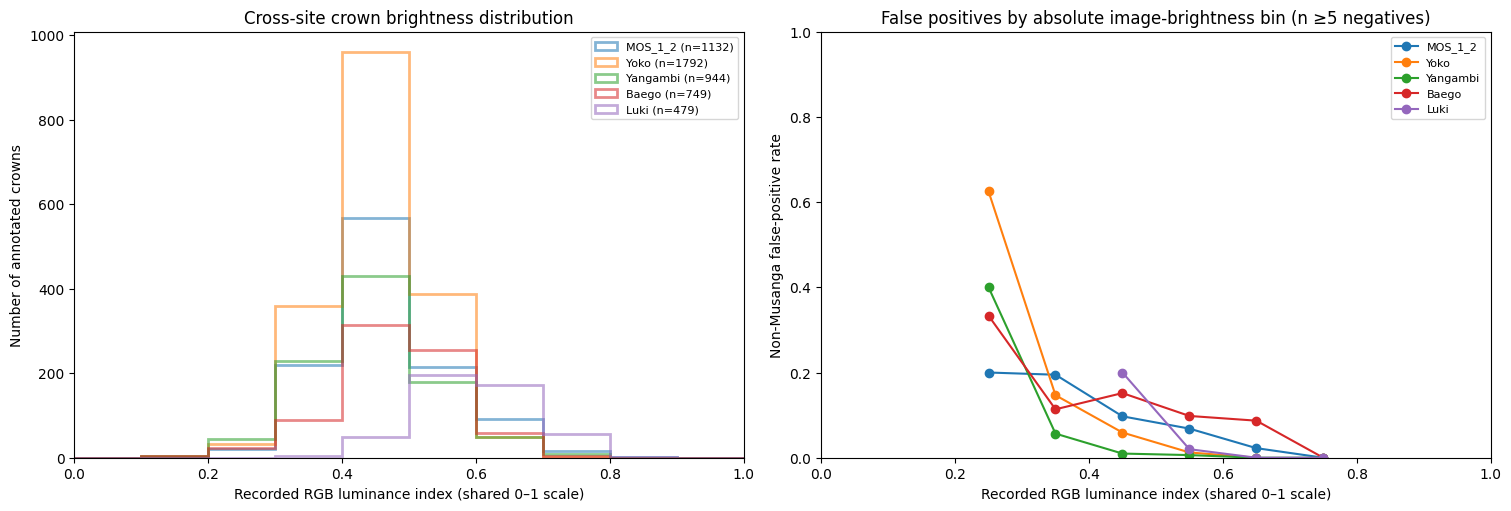

,site,crowns,crowns_with_prediction,median_RGB_index,p10_RGB_index,p90_RGB_index,dark_under_0p4_pct,bright_over_0p6_pct,mean_predicted_score
0,Baego,749,749,0.483,0.378,0.594,15.621,8.545,0.510
1,Luki,479,479,0.592,0.495,0.707,0.626,48.017,0.376
2,MOS_1_2,1132,1132,0.457,0.364,0.595,21.378,9.717,0.487
3,Yangambi,944,944,0.441,0.337,0.563,29.449,5.932,0.478
4,Yoko,1792,1792,0.453,0.368,0.545,22.042,2.790,0.532


Original sources and U-Net maps unchanged. New outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/KVO_work/V2/02_frozen_baseline/by_luki_reference/d957b570055bf5dd


In [8]:
# Exact common RGB luminance intervals, shared across all forests.
# Brightness index defined in V2/01: (.2126 R + .7152 G + .0722 B) / 255,
# using recorded uint8 image values. Units are IMAGE DIGITAL NUMBERS, NOT irradiance.
FIXED_EDGES02=np.linspace(0,1,11)
FIXED_LABELS02=[f"{FIXED_EDGES02[i]:.1f}–{FIXED_EDGES02[i+1]:.1f}"
                for i in range(len(FIXED_EDGES02)-1)]
CROWN_PRED["fixed_brightness_bin"]=pd.cut(
    CROWN_PRED.median_luminance,
    bins=FIXED_EDGES02,labels=FIXED_LABELS02,include_lowest=True,right=True)
CROWN_PRED.to_csv(OUT/"02_frozen_crown_predictions.csv",index=False)

# Exact same denominators and binning across forests. Report empty bins and both label classes.
FIXED_ROWS02=[]
for site in SITES:
    dat=CROWN_PRED[(CROWN_PRED.site==site)&(CROWN_PRED.qa=="ok")].copy()
    for band in FIXED_LABELS02:
        d=dat[dat.fixed_brightness_bin.astype(str)==band]
        pos=d[d.label==1];neg=d[d.label==0]
        FIXED_ROWS02.append(dict(
            site=site,brightness_bin=band,
            n_all=int(len(d)),n_musanga=int(len(pos)),n_other=int(len(neg)),
            musanga_prevalence=float(d.label.mean()) if len(d) else np.nan,
            mean_predicted_musanga_p=float(d.mean_p.mean()) if len(d) else np.nan,
            median_predicted_musanga_p=float(d.mean_p.median()) if len(d) else np.nan,
            false_positive_rate=float((neg.mean_p>=.5).mean()) if len(neg) else np.nan,
            musanga_recall=float((pos.mean_p>=.5).mean()) if len(pos) else np.nan,
            false_positive_n=int((neg.mean_p>=.5).sum()),
            false_negative_n=int((pos.mean_p<.5).sum()),
            model_evaluation="independent_external" if site=="Luki" else "training_site_apparent"))
FIXED_RESULTS02=pd.DataFrame(FIXED_ROWS02)
FIXED_RESULTS02.to_csv(OUT/"02_common_brightness_bins_metrics.csv",index=False)
print("Identical 0.1-wide brightness intervals used at all five sites.")
print("Crown counts per image-brightness band:")
display(FIXED_RESULTS02.pivot(index="brightness_bin",columns="site",values="n_all").fillna(0).astype(int))
print("False-positive rates within each brightness band (inspect n_other first):")
display(FIXED_RESULTS02.pivot(index="brightness_bin",columns="site",values="false_positive_rate").round(3))
print("Luki external evaluation by shared brightness bands:")
display(FIXED_RESULTS02[FIXED_RESULTS02.site=="Luki"].round(3))

# Common axes and bin breaks across forests (not percentile stretching).
fig,axs=plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
for site in SITES:
    d=CROWN_PRED[(CROWN_PRED.site==site)&(CROWN_PRED.qa=="ok")]
    axs[0].hist(d.median_luminance,bins=FIXED_EDGES02,alpha=.55,
                histtype="step",linewidth=2,label=f"{site} (n={len(d)})")
    z=FIXED_RESULTS02[(FIXED_RESULTS02.site==site)&(FIXED_RESULTS02.n_other>=5)]
    xm=np.array([float(s.split("–")[0])+.05 for s in z.brightness_bin])
    axs[1].plot(xm,z.false_positive_rate,marker="o",label=site)
axs[0].set(xlim=(0,1),xlabel="Recorded RGB luminance index (shared 0–1 scale)",
           ylabel="Number of annotated crowns",
           title="Cross-site crown brightness distribution")
axs[1].set(xlim=(0,1),ylim=(0,1),xlabel="Recorded RGB luminance index (shared 0–1 scale)",
           ylabel="Non-Musanga false-positive rate",
           title="False positives by absolute image-brightness bin (n ≥5 negatives)")
for ax in axs:ax.legend(fontsize=8)
fig.savefig(OUT/"02_cross_site_absolute_brightness_vs_false_positives.png",
            dpi=170,bbox_inches="tight")
display(fig);plt.close(fig)

# A site-independent numerical comparison of the RGB brightness values.
# Note that camera/orthomosaic processing may prevent interpretation as illumination exposure.
CROSS_SUM02=CROWN_PRED.groupby("site").agg(
    crowns=("crown_id","count"),
    crowns_with_prediction=("mean_p","count"),
    median_RGB_index=("median_luminance","median"),
    p10_RGB_index=("median_luminance",lambda v:v.quantile(.10)),
    p90_RGB_index=("median_luminance",lambda v:v.quantile(.90)),
    dark_under_0p4_pct=("median_luminance",lambda v:100*float((v<.4).mean())),
    bright_over_0p6_pct=("median_luminance",lambda v:100*float((v>=.6).mean())),
    mean_predicted_score=("mean_p","mean")).reset_index()
CROSS_SUM02.to_csv(OUT/"02_cross_site_absolute_brightness_summary.csv",index=False)
display(CROSS_SUM02.round(3))
print("Warning: cross-site image brightness is not radiometrically calibrated irradiance.")
print("Original sources and U-Net maps unchanged. New outputs:",OUT)


## 07 — Provenance, limitations and handoff to robust training

Freeze results, baseline threshold and illumination cutoffs. The next experiment should compare photometric augmentation against the same independent Luki reference without adjusting settings to maximize Luki performance.

In [9]:
manifest=dict(
    stage="V2/02 Frozen U-Net crown-level and illumination audit",
    source_maps=str(MAPS),reference_source=str(MERGED),
    crown_probability_score="mean valid frozen U-Net P(Musanga) within each labelled crown",
    pixel_cover_diagnostic="fraction of valid crown pixels with U-Net p >=0.5",
    mean_probability_threshold=CROWN_SCORE_THRESHOLD,
    min_valid_pixels=MIN_CROWN_VALID_PIXELS,min_valid_fraction=.90,
    retained_luki_crowns=int((CROWN_PRED.site=="Luki").sum()),
    luki_positive=int(((CROWN_PRED.site=="Luki")&(CROWN_PRED.label==1)).sum()),
    luki_negative=int(((CROWN_PRED.site=="Luki")&(CROWN_PRED.label==0)).sum()),
    luki_reference_version=LUKI_VERSION,
    external_evaluation="Luki only; four original training forests were used to train frozen production U-Net",
    site_relative_strata="quartiles of crown RGB luminance within each forest",
    cross_site_brightness="fixed 0.1-width bins of shared native RGB digital-number luminance, not radiometric irradiance",
    threshold_selection="not tuned on Luki",
    native_uav_crs="unchanged",outputs=str(OUT))
(OUT/"02_frozen_baseline_manifest.json").write_text(json.dumps(manifest,indent=2))
print("V2 NOTEBOOK 02 COMPLETE:",OUT)
print("NEXT: V2 Notebook 03 — train illumination-robust U-Net on the four original forests.")
print("Do not interpret four training-site apparent metrics as LOSO validation.")


V2 NOTEBOOK 02 COMPLETE: /content/drive/MyDrive/Colab Notebooks/Musanga/KVO_work/V2/02_frozen_baseline/by_luki_reference/d957b570055bf5dd
NEXT: V2 Notebook 03 — train illumination-robust U-Net on the four original forests.
Do not interpret four training-site apparent metrics as LOSO validation.
